# Tessa quickstart

A five-minute introduction to the `tessa` library: the 2-colouring of a lattice,
its capacity, the encode -> run -> decode round trip, the single and pair
encodings, dynamic-range recovery, and how to target a whole device offline.
Everything runs on simulators; no IBM account is needed. Install from a clone of
the repository with `pip install -e ".[notebooks]"`.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import hsv_to_rgb, rgb_to_hsv
from PIL import Image

from tessa import (
    Lattice,
    aer_sampler,
    apply_dynamic_range,
    data_path,
    decode,
    encode,
    graph_from_backend,
)
from tessa.backends import fake_sampler
from tessa.hardware import devices

## 1. Data and address qubits

A coupling graph is 2-coloured into data qubits (D), which hold the values, and
address qubits (A), which act as shared controls. On a square lattice this is a
checkerboard. A data qubit with `m` neighbouring address qubits stores `2**m`
values, one per configuration of its local address register, so the capacity is
`sum(2**degree)` over the data qubits.

In [2]:
lattice = Lattice(3, 4)
print(lattice)
print(lattice.ascii())
print(lattice.capacity_breakdown())

Lattice(rows=3, cols=4, n_qubits=12, n_data=6, capacity=48)
D A D A
A D A D
D A D A
{'n_qubits': 12, 'n_data_qubits': 6, 'n_address_qubits': 6, 'corner': 2, 'edge': 3, 'interior': 1, 'values_from_corners': 8, 'values_from_edges': 24, 'values_from_interior': 16, 'capacity': 48}


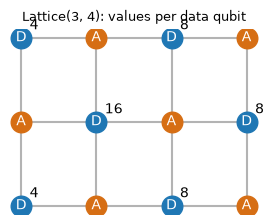

In [3]:
fig, ax = plt.subplots(figsize=(3.2, 2.4))
for group in lattice.groups:
    r, c = group.site
    for ar, ac in group.address_sites:
        ax.plot([c, ac], [r, ar], color="0.7", zorder=1)
    ax.annotate(f"{group.n_values}", (c, r), xytext=(6, 6), textcoords="offset points")
for q in range(lattice.n_qubits):
    r, c = lattice.site_of_qubit(q)
    data = (r + c) % 2 == 0
    ax.scatter(c, r, s=220, color="#1f77b4" if data else "#d66e14", zorder=2)
    ax.text(c, r, "D" if data else "A", color="white", ha="center", va="center")
ax.invert_yaxis()
ax.set_axis_off()
ax.set_title("Lattice(3, 4): values per data qubit", fontsize=9)
plt.show()

## 2. Encode, run, decode

`encode` returns a measurement-free circuit and an `Encoding` (the graph, mode,
clamps and value ranges that `decode` needs). `decode` appends the measurements,
runs them on any SamplerV2-like object and returns the values in their original
shape and units. With a noiseless simulator, shot noise is the only error.

In [4]:
values = np.random.default_rng(0).uniform(-3, 7, lattice.capacity)
circuit, enc = encode(lattice, values)
out = decode(circuit, enc, aer_sampler(lattice, seed=0), shots=200_000)
print(f"{circuit.num_qubits} qubits, depth {circuit.depth()}, {len(values)} values")
print(f"mean absolute error: {np.abs(out - values).mean():.4f}")

12 qubits, depth 34, 48 values
mean absolute error: 0.0165


## 3. An image: QCAT on a 9x9 lattice

The 21x21 QCAT image (441 values) fits on a 9x9 lattice (81 qubits, capacity 512).
By default `decode` simulates each super-pixel (a data qubit and its address qubits)
as its own small circuit, which is exact for a noiseless device and is what makes
simulations of whole chips possible (Sec. 3 of the paper).

Lattice(rows=9, cols=9, n_qubits=81, n_data=41, capacity=512)


8192 shots, noiseless: mean absolute error 0.0054


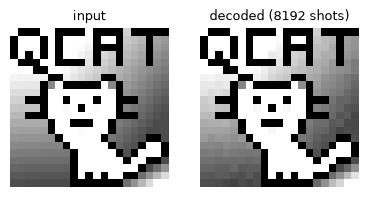

In [5]:
qcat = np.asarray(Image.open(data_path("qcat.png")).convert("L")) / 255
lattice = Lattice(9, 9)
print(lattice)
circuit, enc = encode(lattice, qcat, value_range=(0, 1))
qcat_out = decode(circuit, enc, aer_sampler(lattice, seed=1), shots=8192)
print(f"8192 shots, noiseless: mean absolute error {np.abs(qcat_out - qcat).mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(4.5, 2.4))
for a, im, title in zip(ax, [qcat, qcat_out], ["input", "decoded (8192 shots)"]):
    a.imshow(im, cmap="gray", vmin=0, vmax=1)
    a.set_title(title, fontsize=9)
    a.set_axis_off()
plt.show()

## 4. Single and pair encoding

The pair encoding stores a second value in the phase of each cell, read in a second
basis (X), at no extra two-qubit gates per stored value. Here the colour version of
QCAT is split into value (theta, read in Z) and hue (phi, read in X), as in
Fig. 4 (b) of the paper. The first field is clamped away from the poles (default
0.2 pi) so that the phase is defined.

mode pair, clamps / pi [0.2 0. ]
value MAE 0.0187, hue MAE 0.0226


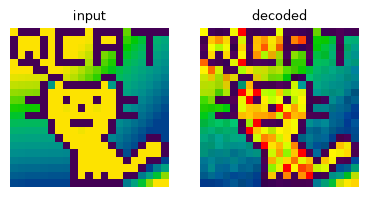

In [6]:
hsv = rgb_to_hsv(np.asarray(Image.open(data_path("qcat_color.png")).convert("RGB")) / 255)
value, hue = hsv[..., 2], hsv[..., 0]
circuit, enc = encode(
    lattice, value, hue, mode="pair", value_range=(0, 1), value_range_b=(0, 1)
)
value_out, hue_out = decode(circuit, enc, aer_sampler(lattice, seed=1), shots=8192)
hue_err = np.abs((hue_out - hue + 0.5) % 1 - 0.5)  # on the circle
print(f"mode {enc.mode}, clamps / pi {np.round(np.array(enc.clamps) / np.pi, 2)}")
print(f"value MAE {np.abs(value_out - value).mean():.4f}, hue MAE {hue_err.mean():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(4.5, 2.4))
for a, (v, h), title in zip(
    ax, [(value, hue), (value_out, hue_out)], ["input", "decoded"]
):
    a.imshow(hsv_to_rgb(np.stack([np.mod(h, 1), np.ones_like(h), np.clip(v, 0, 1)], -1)))
    a.set_title(title, fontsize=9)
    a.set_axis_off()
plt.show()

## 5. A whole device, offline

`graph_from_backend` 2-colours a device's coupling graph with the colouring of
maximum capacity (`ibm_fez`: 156 qubits, capacity 448). `fake_sampler("fez")`
simulates each super-pixel on the physical qubits it occupies, with the per-qubit
calibration of qiskit-ibm-runtime's FakeFez. Noise compresses the range of the
reconstruction towards its centre.

In [7]:
sampler = fake_sampler("fez", seed=1)
graph = graph_from_backend(sampler.backend())
print(graph)
circuit, enc = encode(graph, qcat, value_range=(0, 1))
fez_out = decode(circuit, enc, sampler, shots=8192)
print(f"FakeFez, raw: mean absolute error {np.abs(fez_out - qcat).mean():.3f}")

TessaGraph(n_qubits=156, data=64, address=92, capacity=448)


FakeFez, raw: mean absolute error 0.134


## 6. Dynamic-range recovery

Dynamic-range recovery (App. F of the paper) stretches the reconstruction using one
to three summary statistics of the input; `mean_std` matches its mean and standard
deviation. It needs no extra shots.

FakeFez, mean_std DRR: mean absolute error 0.095


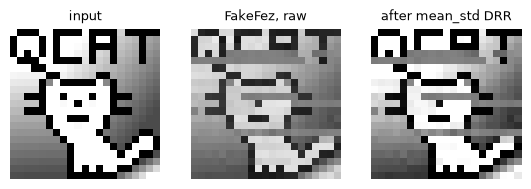

In [8]:
fez_drr = apply_dynamic_range(fez_out, qcat, "mean_std")
print(f"FakeFez, mean_std DRR: mean absolute error {np.abs(fez_drr - qcat).mean():.3f}")

fig, ax = plt.subplots(1, 3, figsize=(6.6, 2.4))
for a, im, title in zip(
    ax, [qcat, fez_out, fez_drr], ["input", "FakeFez, raw", "after mean_std DRR"]
):
    a.imshow(im, cmap="gray", vmin=0, vmax=1)
    a.set_title(title, fontsize=9)
    a.set_axis_off()
plt.show()

## 7. The devices of the paper, from the stored calibration snapshots

`tessa.hardware.devices` ships calibration snapshots of `ibm_phoenix` and `ibm_fez`
(2026-10-09). Here the 28x28 QCAT image (784 values) goes on the Phoenix square
lattice (capacity 792) with a per-qubit noise model from the snapshot (seeded, so
the numbers below are reproducible). `halo=None`
simulates bare super-pixels, as in the paper's simulations; the default,
`halo="traced"`, also adds the noise of the neighbours' gates on the shared address
qubits.

In [9]:
graph = devices.graph("phoenix")
sampler = devices.noisy_sampler("phoenix", seed=1)
qcat28 = np.asarray(Image.open(data_path("qcat28.png")).convert("L")) / 255
circuit, enc = encode(graph, qcat28, value_range=(0, 1))
phoenix_out = decode(circuit, enc, sampler, shots=8192, halo=None)
phoenix_drr = apply_dynamic_range(phoenix_out, qcat28, "mean_std")
print(graph)
print(
    f"raw MAE {np.abs(phoenix_out - qcat28).mean():.3f}, mean_std DRR MAE {np.abs(phoenix_drr - qcat28).mean():.3f}"
)

TessaGraph(n_qubits=120, data=60, address=60, capacity=792)
raw MAE 0.109, mean_std DRR MAE 0.062


## 8. On hardware

The same three calls run on an IBM device; only the sampler changes. Credentials are
read from `$QISKIT_IBM_TOKEN` / `$QISKIT_IBM_INSTANCE` or from the account saved
with `QiskitRuntimeService.save_account`. `per_group=False` submits the whole circuit,
one circuit per measurement basis. Not executed here:

```python
from tessa.backends import ibm_sampler

sampler = ibm_sampler(name="ibm_fez")
graph = graph_from_backend(sampler.backend())
circuit, enc = encode(graph, qcat, value_range=(0, 1))
out = decode(circuit, enc, sampler, per_group=False, shots=8192)
```

For the batch tool used for the pixel-art runs of the paper (`python -m
tessa.hardware`), see `notebooks/rerun_from_raw.ipynb`.